In [1]:
!pip install mediapipe --quiet

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# 1. تحميل موديل Pose Landmarker
model_url = "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_heavy/float16/1/pose_landmarker_heavy.task"
!wget -q -O pose_landmarker.task {model_url}

# 2. إعداد الـ Landmarker
base_options = python.BaseOptions(model_asset_path='pose_landmarker.task')
options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    output_segmentation_masks=False)
detector = vision.PoseLandmarker.create_from_options(options)

print("✅✅ AMAZING! The NEW MediaPipe Pose Landmarker is ready.")

# 3. تجربة سريعة
import numpy as np
dummy_frame = np.zeros((256, 256, 3), dtype=np.uint8)
mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=dummy_frame)
detection_result = detector.detect(mp_image)

print("Test detection finished successfully!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 68.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 8.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have gymnasium 0.29.0 which is incompatible.


2026-01-31 20:43:15.083122: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1769892195.317652      17 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1769892195.382527      17 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1769892195.925093      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769892195.925153      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1769892195.925156      17 computation_placer.cc:177] computation placer alr

✅✅ AMAZING! The NEW MediaPipe Pose Landmarker is ready.
Test detection finished successfully!


W0000 00:00:1769892214.316978      73 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [2]:
import os

base_path = '/kaggle/input/gym-workoutexercises-video'

print("📁 Dataset structure:\n")
for item in os.listdir(base_path):
    item_path = os.path.join(base_path, item)
    if os.path.isdir(item_path):
        print(f"  📂 {item}/")
        for sub in os.listdir(item_path)[:3]:  # First 3 only
            print(f"      └── {sub}")

📁 Dataset structure:

  📂 raw_data/
      └── raw_data
  📂 verified_data/
      └── verified_data
  📂 test/
      └── test


In [3]:
import os
import cv2
import mediapipe as mp
import pandas as pd
from tqdm import tqdm
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# 1. إعداد الـ Detector
base_options = python.BaseOptions(model_asset_path='pose_landmarker.task')
options = vision.PoseLandmarkerOptions(base_options=base_options, output_segmentation_masks=False)
detector = vision.PoseLandmarker.create_from_options(options)

# 2. 🔥 نستخدم كل المسارات المتاحة (raw + verified + test)
DATASET_PATHS = [
    # Verified Data (أنظف)
    '/kaggle/input/gym-workoutexercises-video/verified_data/verified_data/data_btc_10s',
    '/kaggle/input/gym-workoutexercises-video/verified_data/verified_data/data_crawl_10s',
    # Raw Data (أكتر تنوع)
    '/kaggle/input/gym-workoutexercises-video/raw_data/raw_data/data-btc',
    '/kaggle/input/gym-workoutexercises-video/raw_data/raw_data/data-crawl',
    # Test Data (داتا إضافية)
    '/kaggle/input/gym-workoutexercises-video/test/test',
]

# 3. تنظيف الأسماء
def normalize_label(label):
    label = label.lower().replace('-', ' ').replace('_', ' ').strip()
    corrections = {
        'lateral raise': 'lateral raises',
        'push up': 'push up',
        'pull up': 'pull up',
        'tricep pushdown': 'tricep pushdown',
    }
    return corrections.get(label, label)

# 4. إعداد الأعمدة
columns = ['label'] + [f'{c}{i}' for i in range(33) for c in ['x', 'y', 'z', 'v']]
data_list = []

# 5. جمع كل الفيديوهات
all_videos = []
for dataset_path in DATASET_PATHS:
    if not os.path.exists(dataset_path):
        print(f"⚠️ Path not found: {dataset_path}")
        continue
    for exercise in os.listdir(dataset_path):
        exercise_path = os.path.join(dataset_path, exercise)
        if not os.path.isdir(exercise_path):
            continue
        for video_name in os.listdir(exercise_path):
            if video_name.endswith(('.mp4', '.avi', '.mov', '.mkv')):
                all_videos.append((exercise, os.path.join(exercise_path, video_name)))

print(f"🎬 Found {len(all_videos)} videos to process.\n")

# 6. 🔥 المعالجة مع Sampling أذكى
for i, (exercise, video_path) in enumerate(tqdm(all_videos, desc="🏋️ Extracting")):
    try:
        cap = cv2.VideoCapture(video_path)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        
        # 🔥 نحدد 15 نقطة موزعة على طول الفيديو (بداية، نص، نهاية الحركة)
        if total_frames > 15:
            sample_points = [int(total_frames * p) for p in [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8, 0.9, 0.95]]
        else:
            sample_points = list(range(0, total_frames, 2))
        
        for frame_idx in sample_points:
            cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
            ret, frame = cap.read()
            if not ret:
                continue
                
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
            detection_result = detector.detect(mp_image)
            
            if detection_result.pose_landmarks:
                row = [normalize_label(exercise)]
                for lm in detection_result.pose_landmarks[0]:
                    row += [lm.x, lm.y, lm.z, lm.visibility if lm.visibility else 0.0]
                data_list.append(row)
        
        cap.release()
        
        # Checkpoint كل 200 فيديو
        if (i + 1) % 200 == 0:
            temp_df = pd.DataFrame(data_list, columns=columns)
            temp_df.to_csv('workout_pose_data_checkpoint.csv', index=False)
            
    except:
        continue

# 7. الحفظ النهائي
df = pd.DataFrame(data_list, columns=columns)
df.to_csv('workout_pose_data.csv', index=False)

print(f"\n🎉 Done! Rows: {len(df)}")
print(f"\n📊 Distribution:")
print(df['label'].value_counts())

W0000 00:00:1769892214.815434      78 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1769892214.930863      78 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


🎬 Found 2618 videos to process.



🏋️ Extracting:  98%|█████████▊| 2562/2618 [3:45:39<04:43,  5.06s/it][h264 @ 0x3570cd00] mmco: unref short failure
[h264 @ 0x3570cd00] mmco: unref short failure
🏋️ Extracting: 100%|██████████| 2618/2618 [3:49:57<00:00,  5.27s/it]



🎉 Done! Rows: 37341

📊 Distribution:
label
barbell biceps curl    2731
plank                  2654
push up                2201
bench press            2195
squat                  1942
lat pulldown           1920
tricep pushdown        1907
chest fly machine      1889
deadlift               1801
incline bench press    1677
hammer curl            1675
t bar row              1585
leg raises             1563
lateral raises         1545
pull up                1489
decline bench press    1428
leg extension          1391
hip thrust             1301
russian twist          1250
romanian deadlift      1206
tricep dips            1005
shoulder press          986
Name: count, dtype: int64


✅ Loaded 37341 rows
📊 Balanced dataset: 35560 rows
📊 Training: 28448, Testing: 7112

🏋️ Training with balanced weights...

🔄 Running Cross-Validation...
CV Scores: [0.95809899 0.95275591 0.95374016 0.96794151 0.85573678]
CV Mean: 93.77% (+/- 4.13%)

🎯 Test Accuracy: 96.23%

📋 Classification Report:
                     precision    recall  f1-score   support

barbell biceps curl       0.95      0.92      0.94       400
        bench press       0.93      0.95      0.94       400
  chest fly machine       0.97      0.97      0.97       378
           deadlift       0.94      0.95      0.95       360
decline bench press       0.93      0.95      0.94       286
        hammer curl       0.97      0.93      0.95       335
         hip thrust       0.95      0.95      0.95       260
incline bench press       0.95      0.97      0.96       335
       lat pulldown       0.97      0.99      0.98       384
     lateral raises       0.97      0.94      0.95       309
      leg extension       0.

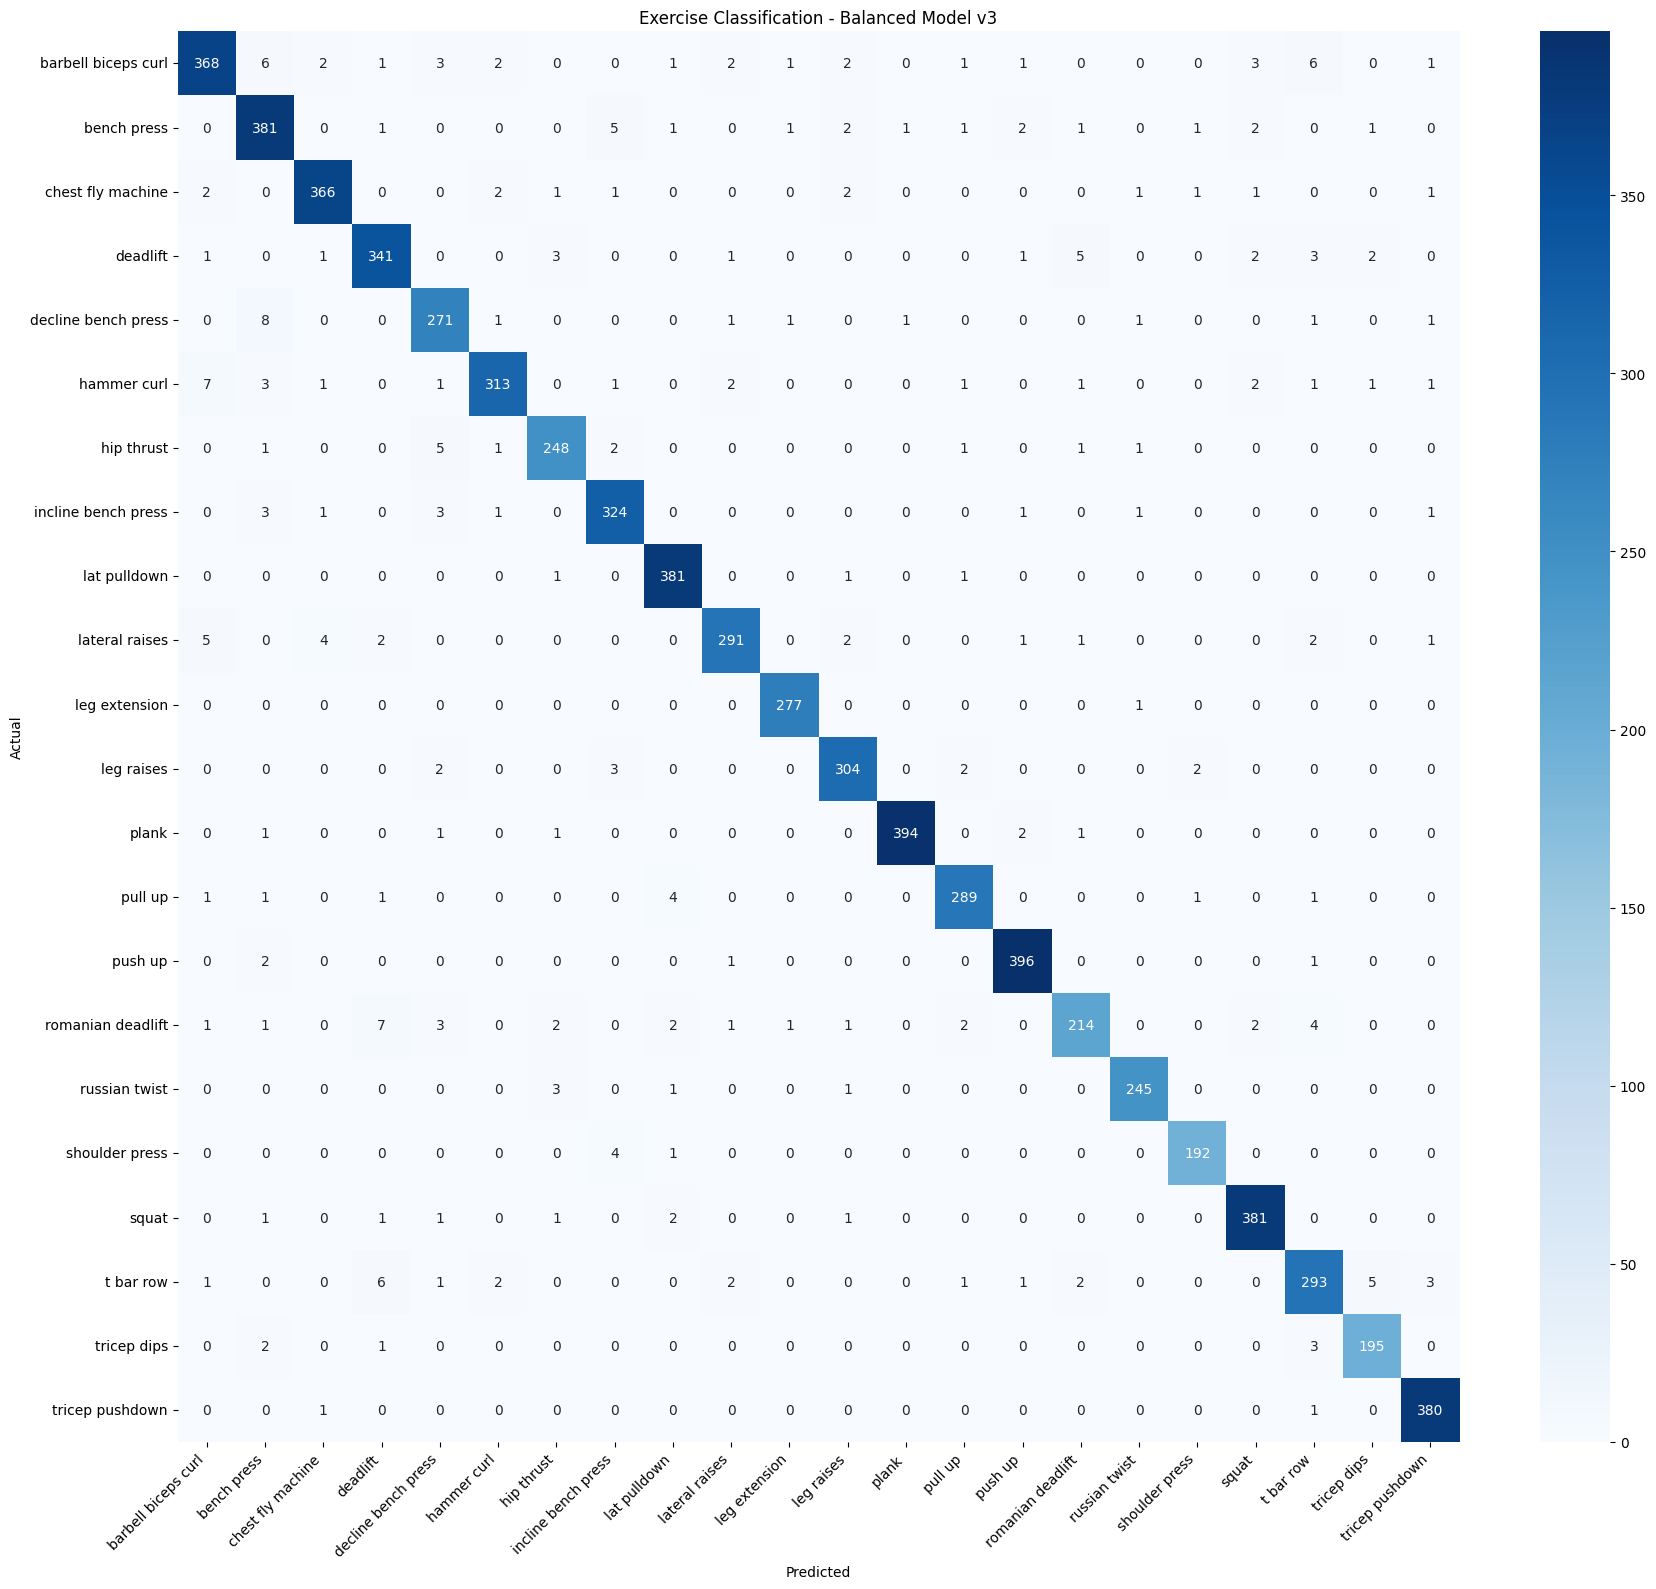


💾 Model saved as 'pose_classifier_v3.pkl'


In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import joblib
import seaborn as sns
import matplotlib.pyplot as plt

# 1. تحميل البيانات
df = pd.read_csv('workout_pose_data.csv')
print(f"✅ Loaded {len(df)} rows")

# 2. معالجة عدم التوازن - تقليل الفئات الكبيرة
max_samples_per_class = 2000  # حد أقصى لكل تمرين
balanced_dfs = []
for label in df['label'].unique():
    label_df = df[df['label'] == label]
    if len(label_df) > max_samples_per_class:
        label_df = label_df.sample(n=max_samples_per_class, random_state=42)
    balanced_dfs.append(label_df)

df_balanced = pd.concat(balanced_dfs, ignore_index=True)
print(f"📊 Balanced dataset: {len(df_balanced)} rows")

# 3. فصل الـ Features عن الـ Label
X = df_balanced.drop('label', axis=1)
y = df_balanced['label']

# 4. تقسيم البيانات
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"📊 Training: {len(X_train)}, Testing: {len(X_test)}")

# 5. تدريب الموديل مع Class Weights
print("\n🏋️ Training with balanced weights...")
model = RandomForestClassifier(
    n_estimators=300,           # أشجار أكتر
    max_depth=25,               # عمق أقل لمنع الـ Overfitting
    min_samples_split=5,        # منع الـ Overfitting
    min_samples_leaf=2,         # منع الـ Overfitting
    class_weight='balanced',    # 🔥 موازنة الفئات تلقائياً
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

# 6. Cross-Validation للتأكد
print("\n🔄 Running Cross-Validation...")
cv_scores = cross_val_score(model, X, y, cv=5)
print(f"CV Scores: {cv_scores}")
print(f"CV Mean: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")

# 7. التقييم
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\n🎯 Test Accuracy: {accuracy * 100:.2f}%")
print("\n📋 Classification Report:")
print(classification_report(y_test, y_pred))

# 8. Confusion Matrix
plt.figure(figsize=(18, 16))
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Exercise Classification - Balanced Model v3')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('confusion_matrix_v3.png')
plt.show()

# 9. حفظ الموديل
joblib.dump(model, 'pose_classifier_v3.pkl')
print("\n💾 Model saved as 'pose_classifier_v3.pkl'")